In [42]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import stft
from scipy.fft import rfft, rfftfreq
from scipy.signal import find_peaks
import mido
from piano2midi.evaluation.metrics import evaluate_notes

In [3]:
audio_path = Path("C:/Users/Deep/Desktop/Deep/Piano2MIDI/piano2midi/data/raw/maestro/piano_sample.mp3")

audio, sr = librosa.load(audio_path, sr=None, mono=False, duration=20)

print(f'Sample rate: {sr} Hz')
print('Audio shape: ', audio.shape)
print(f'Duration: {audio.shape[-1]/sr} seconds')
print('Peak amplitude: ',np.max(np.abs(audio)))

Sample rate: 44100 Hz
Audio shape:  (2, 882000)
Duration: 20.0 seconds
Peak amplitude:  0.48184422


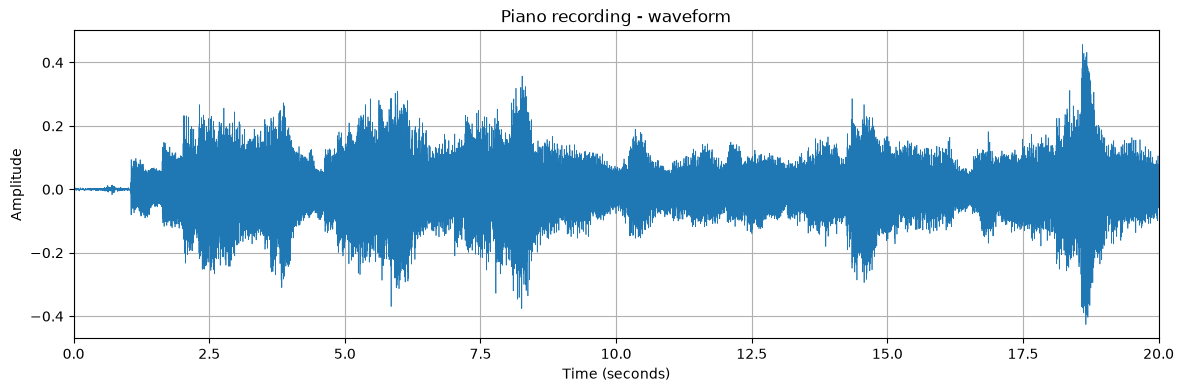

In [4]:
audio_mono = (np.mean(audio, axis=0) if audio.ndim==2 else audio)

time = np.arange(len(audio_mono))/sr

plt.figure(figsize=(14,4))
plt.plot(time, audio_mono, linewidth=0.5)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Piano recording - waveform')
plt.xlim(0, 20)
plt.grid()
plt.show()

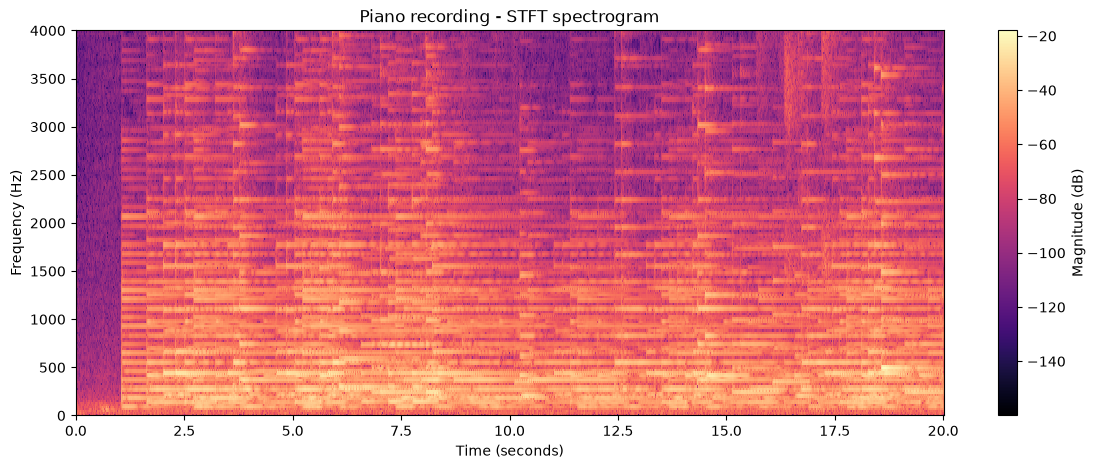

In [5]:
frequencies, times, Zxx = stft(audio_mono, fs=sr, nperseg=2048, noverlap=1536)

magnitude_db = 20*np.log10(np.abs(Zxx)+1e-8)
plt.figure(figsize=(14,5))
plt.pcolormesh(times,frequencies,magnitude_db,shading='auto',cmap='magma')
plt.ylim(0, 4000)
plt.xlabel('Time (seconds)')
plt.ylabel('Frequency (Hz)')
plt.title('Piano recording - STFT spectrogram')
plt.colorbar(label='Magnitude (dB)')
plt.show()

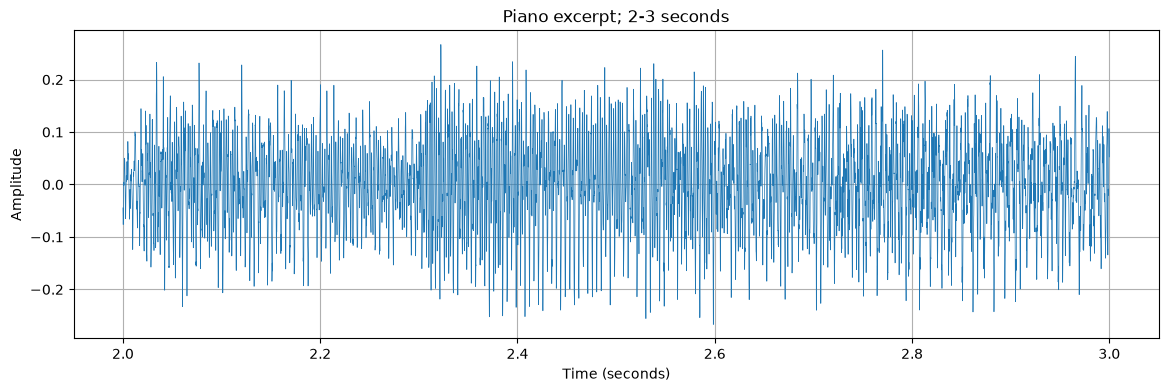

In [6]:
start_time = 2.0
end_time = 3.0

start_sample = int(start_time*sr)
end_sample = int(end_time*sr)

segment = audio_mono[start_sample:end_sample]

plt.figure(figsize=(14,4))
plt.plot(np.arange(len(segment))/sr+start_time,segment,linewidth=0.5)

plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Piano excerpt; 2-3 seconds')
plt.grid()
plt.show()

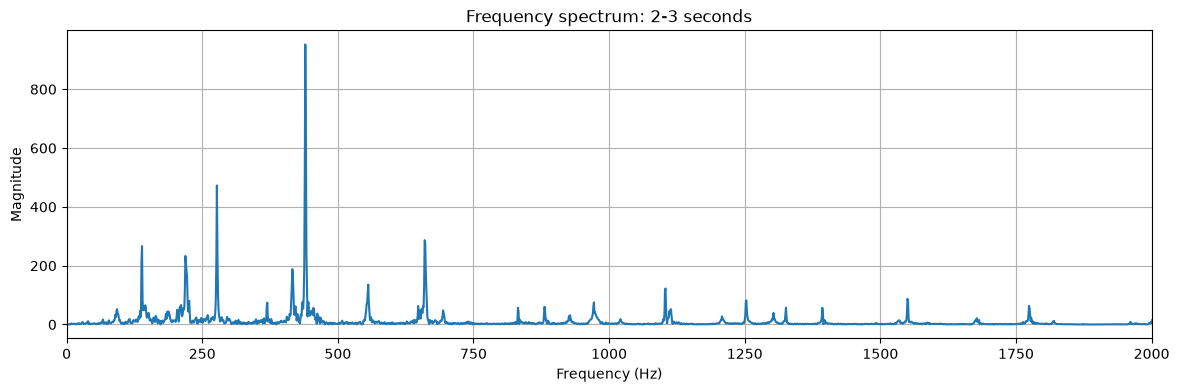

In [7]:
N = len(segment)
windowed_segment = segment*np.hanning(N)

spectrum = np.abs(rfft(windowed_segment))
frequencies = rfftfreq(N, d=1/sr)

plt.figure(figsize=(14,4))
plt.plot(frequencies, spectrum)
plt.xlim(0,2000)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Frequency spectrum: 2-3 seconds')
plt.grid()
plt.show()

In [8]:
valid = frequencies>=40

peaks, properties = find_peaks(spectrum[valid], prominence=10, distance=10)

valid_frequencies = frequencies[valid]
valid_spectrum = spectrum[valid]

order = np.argsort(valid_spectrum[peaks])[::-1]

for idx in order[:15]:
    peak_idx = peaks[idx]
    print(f'Frequency: {valid_frequencies[peak_idx]:7.2f}Hz | '
          f'Magnitude: {valid_spectrum[peak_idx]:.2f}')

Frequency:  440.00Hz | Magnitude: 952.17
Frequency:  277.00Hz | Magnitude: 472.46
Frequency:  660.00Hz | Magnitude: 286.61
Frequency:  139.00Hz | Magnitude: 266.49
Frequency:  219.00Hz | Magnitude: 233.17
Frequency:  416.00Hz | Magnitude: 188.34
Frequency:  556.00Hz | Magnitude: 135.58
Frequency: 1104.00Hz | Magnitude: 122.61
Frequency: 1550.00Hz | Magnitude: 87.21
Frequency: 1253.00Hz | Magnitude: 81.97
Frequency:  972.00Hz | Magnitude: 75.41
Frequency:  370.00Hz | Magnitude: 74.20
Frequency: 1774.00Hz | Magnitude: 63.21
Frequency:  648.00Hz | Magnitude: 62.88
Frequency:  881.00Hz | Magnitude: 60.27


In [9]:
def frequency_to_midi(frequency):
    return int(round(69+12*np.log2(frequency/440)))

def midi_to_note_name(midi_number):
    names = ['C','C#','D','D#','E','F','F#','G','G#','A','A#','B']
    octave = midi_number//12-1
    return f'{names[midi_number%12]}{octave}'

for idx in order[:15]:
    peak_idx = peaks[idx]
    frequency = valid_frequencies[peak_idx]
    midi_number = frequency_to_midi(frequency)

    print(
        f'{frequency:7.2f} Hz -> '
        f'MIDI {midi_number:3d} -> '
        f'{midi_to_note_name(midi_number)}')

 440.00 Hz -> MIDI  69 -> A4
 277.00 Hz -> MIDI  61 -> C#4
 660.00 Hz -> MIDI  76 -> E5
 139.00 Hz -> MIDI  49 -> C#3
 219.00 Hz -> MIDI  57 -> A3
 416.00 Hz -> MIDI  68 -> G#4
 556.00 Hz -> MIDI  73 -> C#5
1104.00 Hz -> MIDI  85 -> C#6
1550.00 Hz -> MIDI  91 -> G6
1253.00 Hz -> MIDI  87 -> D#6
 972.00 Hz -> MIDI  83 -> B5
 370.00 Hz -> MIDI  66 -> F#4
1774.00 Hz -> MIDI  93 -> A6
 648.00 Hz -> MIDI  76 -> E5
 881.00 Hz -> MIDI  81 -> A5


In [10]:
midi_path = 'C:/Users/Deep/Desktop/Deep/Piano2MIDI/piano2midi/data/raw/maestro/piano_sample.midi'
mid = mido.MidiFile(midi_path)

print('Ticks per beat: ', mid.ticks_per_beat)

tempo = 500000
absolute_ticks = 0

for message in mid.merged_track:
    absolute_ticks += message.time

    if message.type == 'set_tempo':
        tempo = message.tempo

    if message.type in ('note_on', 'note_off'):
        seconds = (mido.tick2second(
            absolute_ticks,
            mid.ticks_per_beat,
            tempo
        ))

        if 2.0 <= seconds <= 3.0:
            print(
                f'{seconds:.3f}s | '
                f'{message.type:8} | '
                f'pitch={message.note:3} |'
                f'velocity={message.velocity:3}'
            )

Ticks per beat:  384
2.018s | note_on  | pitch= 57 |velocity= 82
2.062s | note_on  | pitch= 49 |velocity=  0
2.172s | note_on  | pitch= 57 |velocity=  0
2.297s | note_on  | pitch= 57 |velocity= 85
2.499s | note_on  | pitch= 57 |velocity=  0
2.505s | note_on  | pitch= 49 |velocity= 83
2.710s | note_on  | pitch= 42 |velocity= 81
2.727s | note_on  | pitch= 49 |velocity=  0
2.850s | note_on  | pitch= 42 |velocity=  0
2.935s | note_on  | pitch= 42 |velocity= 73


In [11]:
print("Number of tracks:", len(mid.tracks))

for i, track in enumerate(mid.tracks):
    print(
        f"Track {i}: {len(track)} events, "
        f"{sum(msg.type in ('note_on', 'note_off') for msg in track)} note events"
    )

Number of tracks: 2
Track 0: 3 events, 0 note events
Track 1: 66772 events, 35752 note events


In [12]:
for i, track in enumerate(mid.tracks):
    print(f"\nTrack {i}")

    for message in track[:10]:
        print(message)


Track 0
MetaMessage('set_tempo', tempo=500000, time=0)
MetaMessage('time_signature', numerator=4, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
MetaMessage('end_of_track', time=1)

Track 1
program_change channel=0 program=0 time=0
control_change channel=0 control=67 value=0 time=0
note_on channel=0 note=42 velocity=71 time=806
control_change channel=0 control=64 value=37 time=103
control_change channel=0 control=64 value=50 time=15
control_change channel=0 control=64 value=58 time=15
control_change channel=0 control=64 value=62 time=16
control_change channel=0 control=64 value=65 time=15
control_change channel=0 control=64 value=68 time=16
control_change channel=0 control=64 value=73 time=15


In [13]:
mid = mido.MidiFile(midi_path)

absolute_seconds = 0.0
tempo = 500000
ticks_per_beat = mid.ticks_per_beat

for message in mid.merged_track:
    absolute_seconds += mido.tick2second(
        message.time,
        ticks_per_beat,
        tempo
    )

    if message.type == 'set_tempo':
        tempo = message.tempo

    if message.type == 'note_on' and message.velocity>0:
        if 2.0<=absolute_seconds<=3.0:
            print(
                f'{absolute_seconds:.3f}s | '
                f'MIDI {message.note:3} | '
                f'{midi_to_note_name(message.note)} | '
                f'velocity={message.velocity}'
            )

2.018s | MIDI  57 | A3 | velocity=82
2.297s | MIDI  57 | A3 | velocity=85
2.505s | MIDI  49 | C#3 | velocity=83
2.710s | MIDI  42 | F#2 | velocity=81
2.935s | MIDI  42 | F#2 | velocity=73


In [14]:
ground_truth_pitches = [57, 57, 49, 42, 42]

for pitch in sorted(set(ground_truth_pitches)):
    freq = 440*2**((pitch - 69)/12)
    print(
        f'MIDI {pitch:2} ({midi_to_note_name(pitch):3}) '
        f'-> {freq:.2f} Hz'
    )

MIDI 42 (F#2) -> 92.50 Hz
MIDI 49 (C#3) -> 138.59 Hz
MIDI 57 (A3 ) -> 220.00 Hz


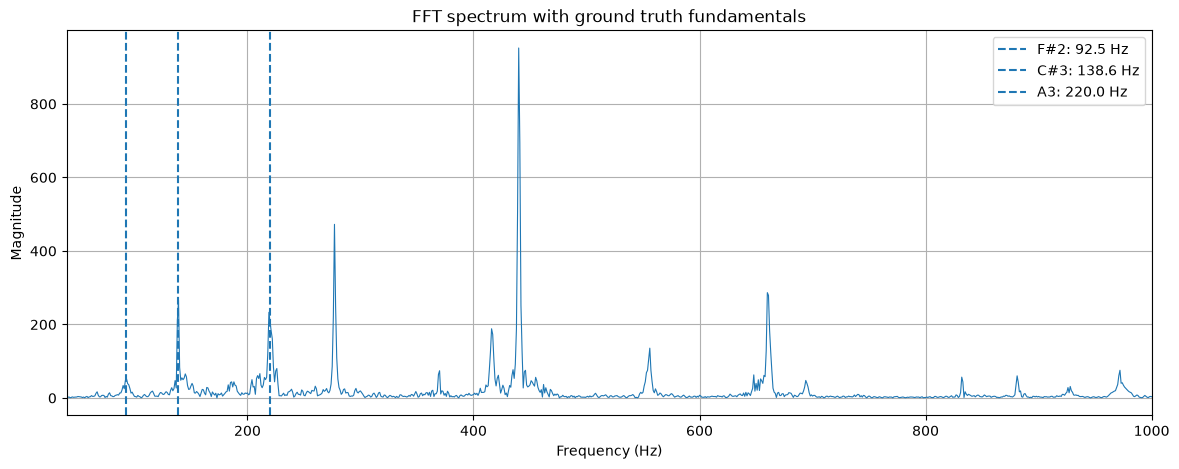

In [17]:
expected_pitches = [42, 49, 57]

plt.figure(figsize=(14,5))
plt.plot(frequencies, spectrum, linewidth=0.8)

for pitch in expected_pitches:
    fundamental = 440*2**((pitch-69)/12)

    plt.axvline(fundamental, linestyle='--', label=f'{midi_to_note_name(pitch)}: {fundamental:.1f} Hz')

plt.xlim(40,1000)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('FFT spectrum with ground truth fundamentals')
plt.legend()
plt.grid()
plt.show()

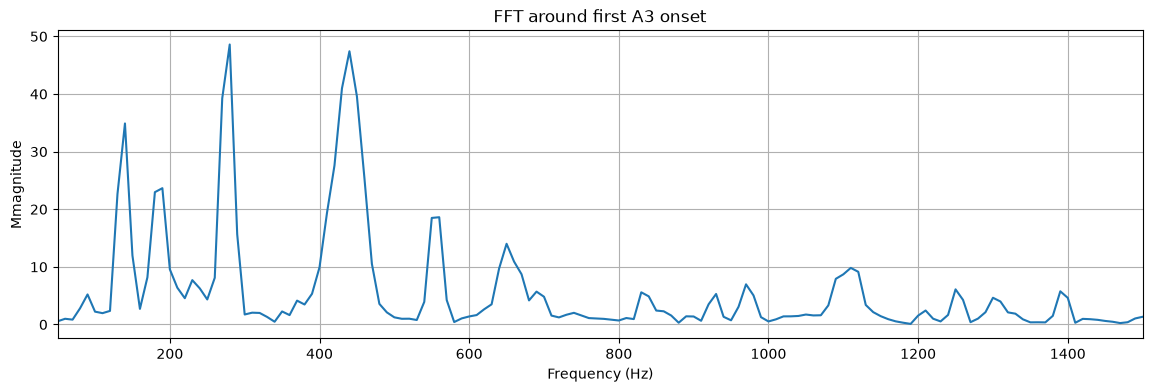

In [20]:
center_time = 2.018
window_duration = 0.100

start_sample = int((center_time - window_duration/2)*sr)
end_sample = int((center_time + window_duration/2)*sr)

short_segment = audio_mono[start_sample:end_sample]

N = len(short_segment)
windowed_segment = short_segment*np.hanning(N)

spectrum_short = np.abs(rfft(windowed_segment))
frequencies_short = rfftfreq(N, d=1/sr)

plt.figure(figsize=(14,4))
plt.plot(frequencies_short, spectrum_short)
plt.xlim(50,1500)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mmagnitude')
plt.title('FFT around first A3 onset')
plt.grid()
plt.show()

In [30]:
def detect_pitch_candidates(
        audio,
        sr,
        frame_size=4096,
        hop_size=1024,
        min_freq=40,
        max_freq=1500,
        prominence = 0.02,
        relative_threshold = 0.10
):
    candidates = []
    frame_times = []

    window = np.hanning(frame_size)

    for start in range(0, len(audio)-frame_size+1, hop_size):
        frame = audio[start:start + frame_size]

        spectrum = np.abs(np.fft.rfft(frame*window))
        freqs = np.fft.rfftfreq(frame_size, d=1/sr)

        valid = (
            (freqs >= min_freq)
            & (freqs <= max_freq)
        )

        local_spectrum = spectrum[valid]
        local_freqs = freqs[valid]

        frame_time = (start+frame_size/2)/sr

        if len(local_spectrum) == 0 or np.max(local_spectrum) == 0:
            candidates.append([])
            frame_times.append(frame_time)
            continue

        normalised = local_spectrum/np.max(local_spectrum)

        peaks, properties = find_peaks(
            normalised,
            prominence=prominence
        )

        strong_peaks = peaks[
            normalised[peaks]>=relative_threshold
        ]

        pitches = set()

        for peak in strong_peaks:
            freq = local_freqs[peak]

            midi_pitch = int(round(
                69+12*np.log2(freq/440)
            ))

            pitches.add(midi_pitch)

        candidates.append(sorted(pitches))
        frame_times.append(frame_time)

    return np.array(frame_times), candidates

In [25]:
frame_times, pitch_candidates = detect_pitch_candidates(
    audio_mono,
    sr
)

print('Frames analysed: ',len(frame_times))
print('First 10 frame times: ',frame_times[:10])
print('First 10 pitch candidates: ', pitch_candidates[:10])

Frames analysed:  858
First 10 frame times:  [0.04643991 0.06965986 0.09287982 0.11609977 0.13931973 0.16253968
 0.18575964 0.20897959 0.23219955 0.2554195 ]
First 10 pitch candidates:  [[41, 46, 53, 56, 57, 60, 62, 65, 68, 71, 74, 76, 80, 81, 86, 89], [41, 49, 53, 56, 59, 62, 64, 73, 76, 79, 81, 86], [36, 41, 45, 48, 53, 56, 58, 64, 67, 70, 74, 76, 79, 82, 85, 87], [41, 46, 53, 57, 64, 66, 67, 69, 77, 78, 80, 85], [41, 46, 52, 57, 60, 66, 68, 69, 71, 74, 75, 82, 86], [41, 46, 50, 57, 60, 66, 69, 70, 74, 75, 77, 79, 82, 87], [36, 41, 46, 50, 55, 60, 70, 71, 74, 76, 77, 82, 86], [43, 52, 60, 63, 65, 68, 70, 74, 76, 79, 86], [33, 43, 49, 57, 62, 65, 68, 69, 70, 74, 76, 77, 80, 83, 86], [41, 48, 52, 55, 58, 60, 62, 65, 68, 69, 72, 74, 76, 78, 80, 83, 86]]


In [26]:
candidate_counts = np.array([
    len(pitches) for pitches in pitch_candidates
])

print('Average candidates per frame: ', candidate_counts.mean())
print('Maximum candidates in a frame: ', candidate_counts.max())
print('Frames with no candidates: ', np.sum(candidate_counts == 0))

Average candidates per frame:  19.36013986013986
Maximum candidates in a frame:  26
Frames with no candidates:  0


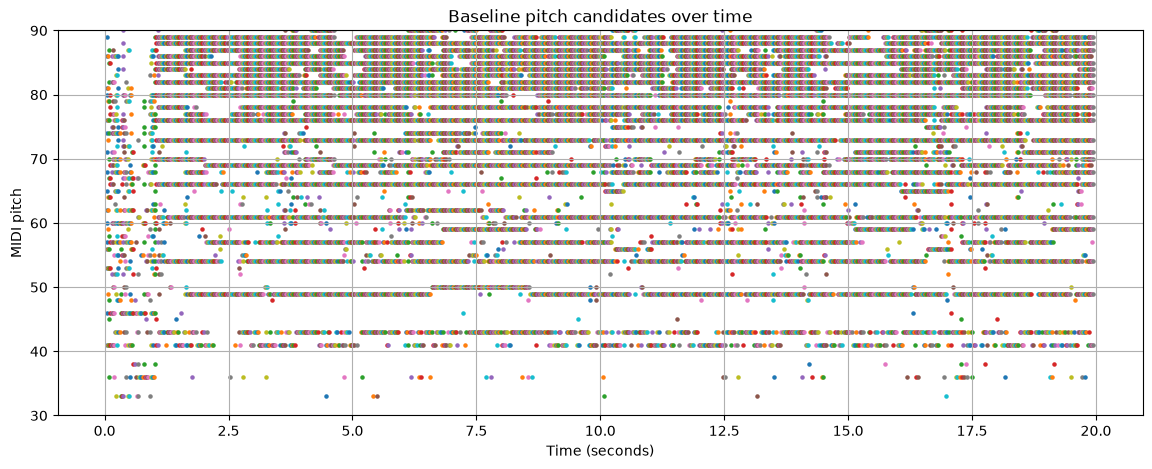

In [27]:
plt.figure(figsize=(14,5))

for time, pitches in zip(frame_times, pitch_candidates):
    if pitches:
        plt.scatter(
            [time]*len(pitches),
            pitches,
            s=5
        )

plt.xlabel('Time (seconds)')
plt.ylabel('MIDI pitch')
plt.title('Baseline pitch candidates over time')
plt.ylim(30, 90)
plt.grid()
plt.show()

In [31]:
for threshold in [0.05, 0.10, 0.20, 0.30]:
    times, candidates = detect_pitch_candidates(
        audio_mono,
        sr,
        relative_threshold=threshold
    )

    counts = np.array([len(p) for p in candidates])

    print(
        f'Threshold={threshold:.2f} | '
        f'Average={counts.mean():.2f} | '
        f'Maximum={counts.max()} | '
        f'Empty frames={np.sum(counts==0)}'
    )

Threshold=0.05 | Average=17.12 | Maximum=24 | Empty frames=0
Threshold=0.10 | Average=12.48 | Maximum=20 | Empty frames=0
Threshold=0.20 | Average=7.20 | Maximum=15 | Empty frames=0
Threshold=0.30 | Average=4.88 | Maximum=12 | Empty frames=0


In [32]:
def candidates_to_events(frame_times, candidates, hop_size=1024,sr=44100):
    events = []
    active = {}

    frame_duration = hop_size/sr

    for time, pitches in zip(frame_times, candidates):
        current =set(pitches)

        for pitch in list(active):
            if pitch not in current:
                events.append({
                    'pitch':pitch,
                    'onset':active.pop(pitch),
                    'offset':time
                })

        for pitch in current:
            if pitch not in active:
                active[pitch] = max(0.0, time-frame_duration/2)

    end_time = frame_times[-1] + frame_duration/2

    for pitch, onset in active.items():
        events.append({
            'pitch':pitch,
            'onset':onset,
            'offset':end_time
        })   

    return events

In [33]:
frame_times, pitch_candidates = detect_pitch_candidates(
    audio_mono,
    sr,
    relative_threshold=0.20
)

predicted_events = candidates_to_events(
    frame_times,
    pitch_candidates,
    hop_size=1024,
    sr=sr
)

print('Predicted note events: ',len(predicted_events))
print(*predicted_events[:20], sep='\n')

Predicted note events:  852
{'pitch': 46, 'onset': np.float64(0.034829931972789115), 'offset': np.float64(0.06965986394557823)}
{'pitch': 49, 'onset': np.float64(0.05804988662131519), 'offset': np.float64(0.09287981859410431)}
{'pitch': 53, 'onset': np.float64(0.05804988662131519), 'offset': np.float64(0.11609977324263039)}
{'pitch': 36, 'onset': np.float64(0.08126984126984127), 'offset': np.float64(0.11609977324263039)}
{'pitch': 45, 'onset': np.float64(0.08126984126984127), 'offset': np.float64(0.11609977324263039)}
{'pitch': 48, 'onset': np.float64(0.08126984126984127), 'offset': np.float64(0.11609977324263039)}
{'pitch': 41, 'onset': np.float64(0.034829931972789115), 'offset': np.float64(0.2089795918367347)}
{'pitch': 46, 'onset': np.float64(0.10448979591836735), 'offset': np.float64(0.2089795918367347)}
{'pitch': 50, 'onset': np.float64(0.1509297052154195), 'offset': np.float64(0.2089795918367347)}
{'pitch': 36, 'onset': np.float64(0.1741496598639456), 'offset': np.float64(0.20897

In [35]:
def filter_short_events(events, min_duration=0.07):
    return[
        event for event in events
        if event['offset']-event['onset']>=min_duration
    ]

In [36]:
filtered_events = filter_short_events(
    predicted_events,
    min_duration=0.07
)

print('before filtering: ',len(predicted_events))
print('After filtering: ',len(filtered_events))
print('Removed: ',len(predicted_events)-len(filtered_events))

before filtering:  852
After filtering:  425
Removed:  427


In [40]:
def extract_midi_notes(mid, duration=20.0):
    tempo = 500000
    ticks_per_beat = mid.ticks_per_beat
    current_time = 0.0

    active_notes = {}
    ground_truth = []

    for message in mid.merged_track:
        current_time += mido.tick2second(
            message.time,
            ticks_per_beat,
            tempo
        )

        if message.type == 'set_tempo':
            tempo = message.tempo
            continue

        if message.type not in ('note_on', 'note_off'):
            continue

        is_note_on = (
            message.type == 'note_on' and message.velocity >0
        )

        key = (message.channel, message.note)

        if is_note_on:
            active_notes.setdefault(key, []).append(
                (current_time, message.velocity)
            )
        else:
            starts = active_notes.get(key,[])

            if starts:
                onset, velocity = starts.pop(0)

                if onset<duration:
                    offset = min(current_time, duration)

                    if offset>onset:
                        ground_truth.append({
                            'pitch':message.note,
                            'onset':onset,
                            'offset':offset,
                            'velocity':velocity
                        })

    return sorted(
        ground_truth,
        key=lambda note: note['onset']
    )

In [41]:
ground_truth_20s = extract_midi_notes(mid,duration=20.0)

print('Reference notes: ',len(ground_truth_20s))
print('First 10 reference notes: ')

for note in ground_truth_20s[:10]:
    print(note)

Reference notes:  97
First 10 reference notes: 
{'pitch': 42, 'onset': 1.0494791666666665, 'offset': 1.7174479166666663, 'velocity': 71}
{'pitch': 49, 'onset': 1.6249999999999996, 'offset': 2.0624999999999996, 'velocity': 78}
{'pitch': 57, 'onset': 2.018229166666666, 'offset': 2.1718749999999996, 'velocity': 82}
{'pitch': 57, 'onset': 2.2968749999999996, 'offset': 2.498697916666666, 'velocity': 85}
{'pitch': 49, 'onset': 2.5052083333333326, 'offset': 2.7265624999999996, 'velocity': 83}
{'pitch': 42, 'onset': 2.709635416666666, 'offset': 2.850260416666666, 'velocity': 81}
{'pitch': 42, 'onset': 2.9348958333333326, 'offset': 3.3020833333333326, 'velocity': 73}
{'pitch': 49, 'onset': 3.207031249999999, 'offset': 3.519531249999999, 'velocity': 80}
{'pitch': 57, 'onset': 3.492187499999999, 'offset': 3.5807291666666656, 'velocity': 73}
{'pitch': 61, 'onset': 3.621093749999999, 'offset': 3.8606770833333326, 'velocity': 94}


In [43]:
results = evaluate_notes(
    ground_truth_20s,
    filtered_events,
    onset_tolerance=0.05, offset_tolerance=0.05
)

print(results)

{'TP': 4, 'FP': 421, 'FN': 93, 'precision': 0.009411764705882352, 'recall': 0.041237113402061855, 'F1': 0.01532567049808429}


In [44]:
gt_1s = [
    note for note in ground_truth_20s
    if note['onset']<1.0
]

pred_1s = [
    note for note in filtered_events
    if note['onset']<1.0
]

print('Reference notes: ', len(gt_1s))
print('Predicted events: ', len(pred_1s))

print('\nReference: ')
for note in gt_1s:
    print(note)

print('\nPredictions: ')
for note in pred_1s[:20]:
    print(note)

print('\nMetrics: ')
print(evaluate_notes(gt_1s,pred_1s))

Reference notes:  0
Predicted events:  10

Reference: 

Predictions: 
{'pitch': 41, 'onset': np.float64(0.034829931972789115), 'offset': np.float64(0.2089795918367347)}
{'pitch': 46, 'onset': np.float64(0.10448979591836735), 'offset': np.float64(0.2089795918367347)}
{'pitch': 48, 'onset': np.float64(0.24380952380952384), 'offset': np.float64(0.3250793650793651)}
{'pitch': 33, 'onset': np.float64(0.313469387755102), 'offset': np.float64(0.3947392290249433)}
{'pitch': 46, 'onset': np.float64(0.313469387755102), 'offset': np.float64(0.5340589569160997)}
{'pitch': 41, 'onset': np.float64(0.4992290249433107), 'offset': np.float64(0.5804988662131519)}
{'pitch': 36, 'onset': np.float64(0.6849886621315192), 'offset': np.float64(0.7894784580498866)}
{'pitch': 36, 'onset': np.float64(0.8010884353741496), 'offset': np.float64(0.905578231292517)}
{'pitch': 36, 'onset': np.float64(0.9171882086167801), 'offset': np.float64(1.0216780045351475)}
{'pitch': 46, 'onset': np.float64(0.9171882086167801), '